## Employee Salary Prediction using Lasso Regression.

## STEP 2: Load the dataset in Python

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("job_salary_prediction_dataset.csv")

In [3]:
df.head()

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


In [4]:
df.shape

(250000, 10)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   job_title         250000 non-null  object
 1   experience_years  250000 non-null  int64 
 2   education_level   250000 non-null  object
 3   skills_count      250000 non-null  int64 
 4   industry          250000 non-null  object
 5   company_size      250000 non-null  object
 6   location          250000 non-null  object
 7   remote_work       250000 non-null  object
 8   certifications    250000 non-null  int64 
 9   salary            250000 non-null  int64 
dtypes: int64(4), object(6)
memory usage: 19.1+ MB


In [6]:
df.isnull().sum()

job_title           0
experience_years    0
education_level     0
skills_count        0
industry            0
company_size        0
location            0
remote_work         0
certifications      0
salary              0
dtype: int64

In [7]:
df.duplicated().sum()

0

## STEP 3: Statistical Analysis

In [8]:
df.describe()

,experience_years,skills_count,certifications,salary
count,250000.000000,250000.000000,250000.000000,250000.000000
mean,10.005408,9.997812,2.491928,145718.080524
std,6.060602,5.479288,1.706475,37407.952729
min,0.000000,1.000000,0.000000,31867.000000
25%,5.000000,5.000000,1.000000,119358.000000
50%,10.000000,10.000000,2.000000,143453.000000
75%,15.000000,15.000000,4.000000,169492.000000
max,20.000000,19.000000,5.000000,333046.000000


In [9]:
df.describe(include="object")

,job_title,education_level,industry,company_size,location,remote_work
count,250000,250000,250000,250000,250000,250000
unique,12,5,10,5,10,3
top,Backend Developer,Master,Finance,Large,Australia,No
freq,21125,50352,25393,50254,25258,83621


## STEP 4: Exploratory Data Analysis (EDA).
EDA means understanding our dataset through statistics and visualizations before building a Machine Learning model.

In this step, we'll investigate:
1. Salary distribution.
2. Relationship between experience and salary.
3. Salary differences across job titles.
4. Education level and salary.
5. Outliers in salary.

In [10]:
df['salary'].describe()

count    250000.000000
mean     145718.080524
std       37407.952729
min       31867.000000
25%      119358.000000
50%      143453.000000
75%      169492.000000
max      333046.000000
Name: salary, dtype: float64

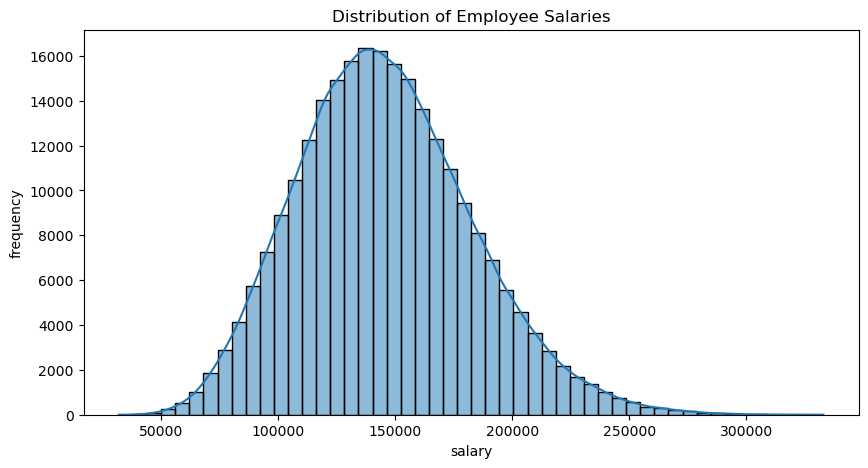

In [11]:
## Salary distribution
plt.figure(figsize=(10,5))
sns.histplot(df['salary'],bins=50,kde=True)
plt.title('Distribution of Employee Salaries')
plt.xlabel('salary')
plt.ylabel('frequency')
plt.show()


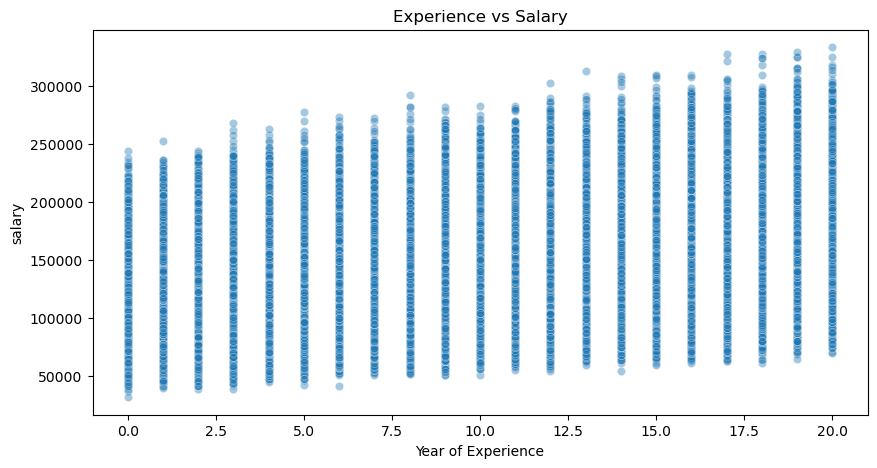

In [12]:
##Experience vs Salary
plt.figure(figsize=(10,5))
sns.scatterplot(
    data=df,
    x='experience_years',
    y='salary',
    alpha=0.4
)
plt.title('Experience vs Salary')
plt.xlabel('Year of Experience')
plt.ylabel('salary')
plt.show()

In [13]:
#Average salary by job title
job_salary =df.groupby('job_title')['salary'].mean().sort_values(ascending=False)
print(job_salary)

job_title
AI Engineer                  173498.480640
Machine Learning Engineer    163022.504570
Product Manager              157594.932029
Cloud Engineer               152102.535290
DevOps Engineer              149959.266791
Cybersecurity Analyst        148697.695548
Data Scientist               147258.214409
Software Engineer            141739.521460
Backend Developer            139202.768663
Frontend Developer           132653.842485
Business Analyst             122551.231354
Data Analyst                 119891.696603
Name: salary, dtype: float64


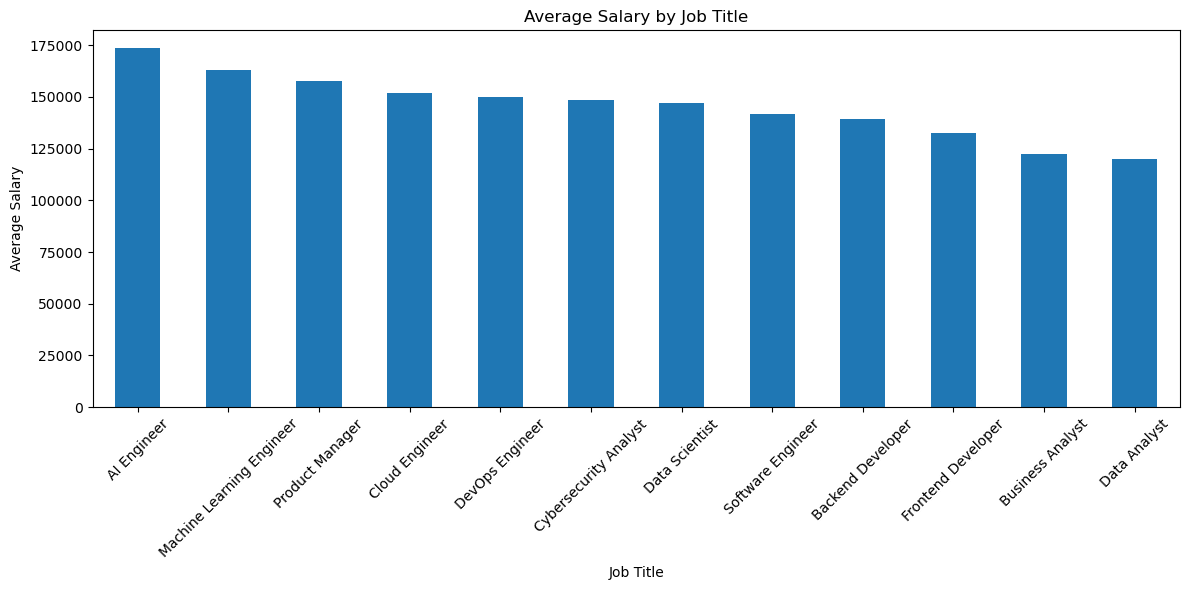

In [14]:
plt.figure(figsize=(12, 6))

job_salary.plot(kind='bar')

plt.title('Average Salary by Job Title')
plt.xlabel('Job Title')
plt.ylabel('Average Salary')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
education_salary = df.groupby('education_level')['salary'].mean().sort_values(ascending=False)

print(education_salary)

education_level
PhD            163976.005295
Master         153305.307833
Bachelor       142410.531291
Diploma        137158.574976
High School    131715.336243
Name: salary, dtype: float64


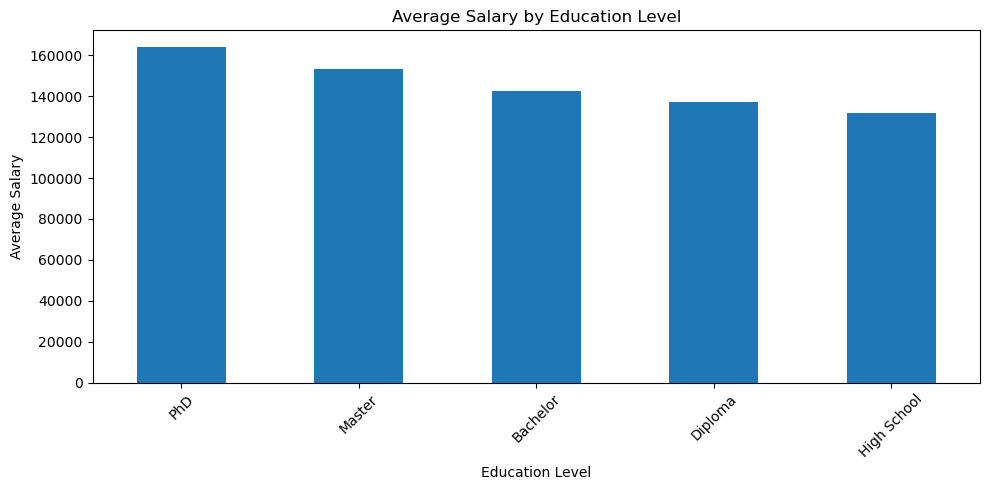

In [16]:
plt.figure(figsize=(10, 5))

education_salary.plot(kind='bar')

plt.title('Average Salary by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Average Salary')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## STEP 5: Outlier Detection

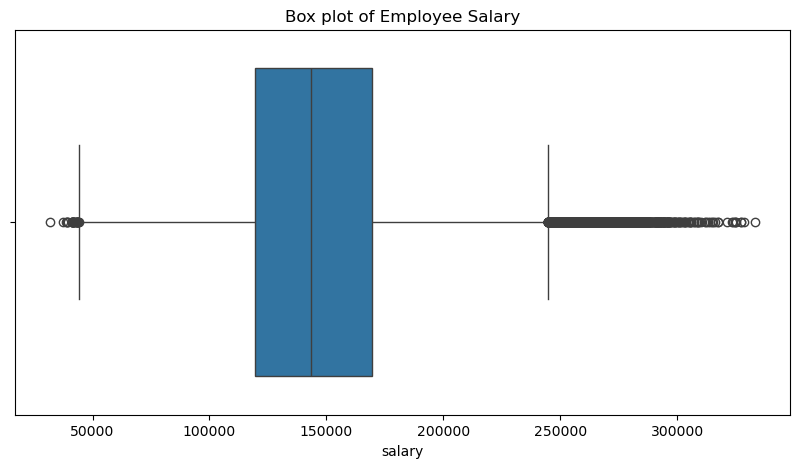

In [17]:
plt.figure(figsize=(10,5))
sns.boxplot(x=df['salary'])
plt.title('Box plot of Employee Salary')
plt.xlabel('salary')
plt.show()

In [18]:
#Now calculate the exact outlier boundaries
Q1 = df['salary'].quantile(0.25)

Q3 = df['salary'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 119358.0
Q3: 169492.0
IQR: 50134.0
Lower Bound: 44157.0
Upper Bound: 244693.0


In [19]:
outliers = df[
    (df['salary'] < lower_bound) |
    (df['salary'] > upper_bound)
]

print("Total Outliers:", len(outliers))

print("Outlier Percentage:",
      (len(outliers) / len(df)) * 100)

Total Outliers: 2336
Outlier Percentage: 0.9344


## start actual model preparation

In [20]:
from sklearn.model_selection import train_test_split

In [21]:
X =df.drop('salary',axis=1)
Y =df['salary']

In [22]:
print(X.shape)
print(Y.shape)

(250000, 9)
(250000,)


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)

## Step 9: Separate Numerical and Categorical Features
Before applying Lasso Regression, we need to convert categorical text columns into numerical values. Lasso Regression works with numerical data, not raw text.

In [24]:
numerical_features = [
    'experience_years',
    'skills_count',
    'certifications'
]

In [25]:
categorical_features = [
    'job_title',
    'education_level',
    'industry',
    'company_size',
    'location',
    'remote_work'
]

In [26]:
print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['experience_years', 'skills_count', 'certifications']
Categorical Features: ['job_title', 'education_level', 'industry', 'company_size', 'location', 'remote_work']


## Step 10: One-Hot Encoding and Feature Scaling
One-Hot Encoding: Converts categorical text values into numerical columns.
StandardScaler: Scales numerical features to a comparable range. This is important because Lasso applies a penalty to model coefficients.


In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [28]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [29]:
print(df.columns.tolist())

['job_title', 'experience_years', 'education_level', 'skills_count', 'industry', 'company_size', 'location', 'remote_work', 'certifications', 'salary']


In [30]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

## create and Train the Lasso Regression Model

In [31]:
from sklearn.linear_model import Lasso
lasso_model = Lasso(alpha=1.0, max_iter=10000)

In [32]:
lasso_model.fit(X_train_processed, y_train)

Lasso(max_iter=10000)

In [33]:
y_pred = lasso_model.predict(X_test_processed)

In [34]:
comparison =pd.DataFrame({
    'Actual salary':y_test.values[:10],
    'predicted salary':y_pred[:10]
})
print(comparison)

   Actual salary  predicted salary
0         164009     172848.298365
1          79594      89226.254873
2          74090      63806.797184
3         177193     168280.556674
4         120012     117217.027618
5         163369     171747.546319
6         111889     110432.684651
7          75418      60470.494318
8         103067      93116.987120
9         190692     192429.484688


## Step 13: Evaluate the model

In [35]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

In [36]:
mae=mean_absolute_error(y_test,y_pred)
print("MAE:",mae)

MAE: 5435.814312496439


In [37]:
mse = mean_squared_error(y_test, y_pred)
print("MSE:", mse)

MSE: 50771165.42778469


In [38]:
rmse = np.sqrt(mse)
print("RMSE:", rmse)

RMSE: 7125.388791342174


In [39]:
r2 = r2_score(y_test, y_pred)
print("R2 Score:", r2)

R2 Score: 0.9634703979647994


In [40]:
coefficients = lasso_model.coef_

total_features = len(coefficients)

zero_features = np.sum(coefficients == 0)

non_zero_features = np.sum(coefficients != 0)

print("Total Features:", total_features)
print("Zero Coefficients:", zero_features)
print("Non-Zero Coefficients:", non_zero_features)

Total Features: 48
Zero Coefficients: 6
Non-Zero Coefficients: 42


## Compare Linear Regression vs Lasso Regression

In [41]:
from sklearn.linear_model import LinearRegression

In [42]:
linear_model = LinearRegression()

In [43]:
linear_model.fit(X_train_processed, y_train)

LinearRegression()

In [44]:
linear_pred = linear_model.predict(X_test_processed)

In [45]:
linear_mae = mean_absolute_error(y_test, linear_pred)

linear_mse = mean_squared_error(y_test, linear_pred)

linear_rmse = np.sqrt(linear_mse)

linear_r2 = r2_score(y_test, linear_pred)

print("Linear Regression Results")
print("MAE:", linear_mae)
print("MSE:", linear_mse)
print("RMSE:", linear_rmse)
print("R2 Score:", linear_r2)

Linear Regression Results
MAE: 5436.0969586494775
MSE: 50773076.89164505
RMSE: 7125.522920575377
R2 Score: 0.9634690226760201


In [46]:
comparison = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Linear Regression': [
        linear_mae, linear_mse, linear_rmse, linear_r2
    ],
    'Lasso Regression': [
        mae, mse, rmse, r2
    ]
})

print(comparison)

     Metric  Linear Regression  Lasso Regression
0       MAE       5.436097e+03      5.435814e+03
1       MSE       5.077308e+07      5.077117e+07
2      RMSE       7.125523e+03      7.125389e+03
3  R2 Score       9.634690e-01      9.634704e-01


In [48]:
alpha_values = [0.1, 1, 10, 100]

for alpha in alpha_values:

    model = Lasso(
        alpha=alpha,
        max_iter=10000,
        selection='random',
        random_state=42
    )

    model.fit(X_train_processed, y_train)

    predictions = model.predict(X_test_processed)

    print("Alpha:", alpha)
    print("MAE:", mean_absolute_error(y_test, predictions))
    print("R2 Score:", r2_score(y_test, predictions))
    print("Zero Coefficients:", np.sum(model.coef_ == 0))
    print("--------------------------")

C:\Users\poorv\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:658: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 1662528185351.9033, tolerance: 28034413392.753613
  model = cd_fast.sparse_enet_coordinate_descent(


Alpha: 0.1
MAE: 5436.043147241113
R2 Score: 0.9634692372824287
Zero Coefficients: 0
--------------------------
Alpha: 1
MAE: 5435.816667147863
R2 Score: 0.9634702651856566
Zero Coefficients: 3
--------------------------
Alpha: 10
MAE: 5434.984129932899
R2 Score: 0.9634631476218025
Zero Coefficients: 19
--------------------------
Alpha: 100
MAE: 5558.736869785735
R2 Score: 0.9617078585080895
Zero Coefficients: 21
--------------------------


## Step 23: Train the selected Lasso model

In [49]:
final_lasso = Lasso(
    alpha=10,
    max_iter=10000
)

final_lasso.fit(X_train_processed, y_train)

Lasso(alpha=10, max_iter=10000)

In [50]:
final_pred = final_lasso.predict(X_test_processed)

final_mae = mean_absolute_error(y_test, final_pred)
final_rmse = np.sqrt(mean_squared_error(y_test, final_pred))
final_r2 = r2_score(y_test, final_pred)

print("Final Lasso Model")
print("MAE:", final_mae)
print("RMSE:", final_rmse)
print("R2 Score:", final_r2)
print("Zero Coefficients:", np.sum(final_lasso.coef_ == 0))

Final Lasso Model
MAE: 5435.000336681034
RMSE: 7126.089453827217
R2 Score: 0.9634632134641623
Zero Coefficients: 19


In [51]:
import joblib

joblib.dump(final_lasso, 'final_lasso_salary_model.pkl')
joblib.dump(preprocessor, 'salary_preprocessor.pkl')

['salary_preprocessor.pkl']

In [53]:
import os

print("Lasso Model:",
      os.path.exists("final_lasso_salary_model.pkl"))

print("Preprocessor:",
      os.path.exists("salary_preprocessor.pkl"))

Lasso Model: True
Preprocessor: True
